## 06 — Sliding-window check, paper gene list (n=150, k=9)

### Aim
* Apply the corrected sliding-window procedure from `05_sliding_window_corrected.ipynb` (fixed Stage 1, step-1 windows, Stage-2-only refits) to the **paper-aligned Stage 1 baseline** — the n=150 cohort deconvolved with the paper's 282-gene Table S3 list instead of the local Stage-0 probe list — producing a single visualization, as requested.
* Question: under the paper's own gene list, does the ambiguous/broad profile's reference-correlation signature sharpen with enrichment (real compartment) or stay flat (artifact), as already found for the Stage-0-probe baseline in notebook 05?

### Input
* The existing n=150/k=9 Stage 1 fit using the paper's Table S3 gene list (`data/deconvolution/xdec/stage1_with_refs_k9_n150_paperGenes`, "Run A" from `01_artifact_diagnosis.ipynb` Section 2) — fixed `proportions.tsv` and `cell_type_profiles.tsv`, not refit per window
* `KRT19` bulk TPM expression (same ranking gene as notebook 05; present in the paper's own Table S3 list) for ordering the 150 samples
* 111 cached Stage-2-only outputs (`data/deconvolution/xdec/sliding_window_paperGenes_fixed_stage1/stage2_w*`), one per overlapping 40-sample window (step 1) — the window sample composition is identical to notebook 05 (same ranking), only the fixed proportions differ (Run A's, not the Stage-0-probe baseline's)
* Peng et al. single-cell reference (`refs.tsv`, `ref_metadata.tsv`) and the paper's Table S3 gene list as the shared probe set

### Output
* A standard (non-windowed), all-9-profiles correlation heatmap for the Run A baseline — the same Figure-2A-style panel as notebook 01 Section 2, included here for self-containedness and to motivate the target-profile choice below
* One window × (patient, cell-type) correlation heatmap for the paper-gene baseline's broadest-correlating profile across all 111 windows

### Target profile
Under the paper-gene Stage 1 fit, the broadest-correlating profile (the counterpart to `Profile_7` in the Stage-0-probe baseline) is **`Profile_8`** (breadth 5/10 reference types at r>0.3, vs. 0/10 for every other profile) — identified in `01_artifact_diagnosis.ipynb` Section 2. Profile labels are fit-specific, so this is a different profile index from notebook 05's `Profile_7`, despite asking the same diagnostic question.

### Steps
* Rebuild the patient × cell-type pseudobulk reference (same layout as notebooks 01/04/05)
* Render the standard baseline heatmap for all 9 profiles against the pseudobulk reference, confirming `Profile_8` as the only broadly-correlating row
* For each of the 111 cached windows, correlate `Profile_8`'s window-specific Stage 2 mean expression against the pseudobulk reference over the paper's Table S3 genes
* Render the single windowed heatmap

### Result
* Breadth is high but **not saturated** this time: 6–10/10 cell types and 169–264/270 individual reference columns exceed r>0.3 depending on the window (vs. a flat 10/10 and 270/270 for every window under the Stage-0-probe baseline in notebook 05). A visibly lighter column block is the enteroendocrine-cell reference group — consistently the *weakest*-correlating cell type across essentially every window, a column (cell-type) effect, not a row (enrichment) effect.
* Specificity (top-minus-second reference margin) stays small throughout (0.0003–0.033, i.e. at most ~3%) and has only a **weak positive** relationship with enrichment: Spearman *r* = **0.18** against window mean `KRT19` TPM — far too weak to read as the profile sharpening into a distinct compartment as enrichment increases.
* The heatmap itself is visually uniform blue across nearly its full 111×270 extent, aside from the enteroendocrine-column dip; there is no visible horizontal banding (no row range stands out as systematically darker or lighter than others).

### Conclusion
* Under the paper's own 282-gene Table S3 list, `Profile_8` shows the same qualitative pattern as `Profile_7` did under the Stage-0 probes in notebook 05 — broad, close-to-uniform reference correlation that does not meaningfully sharpen with enrichment for a plausible marker gene — though slightly less extreme (breadth 6–10/10 rather than a flat 10/10, and a small positive rather than negative margin trend). This is additional, gene-list-independent evidence consistent with an NNLS estimation artifact underlying the ambiguous profile, rather than something specific to the local Stage-0 probe selection.


In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Find progress/ from either the notebook directory or progress/ itself.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "tools/XDec_SM/python/xdec.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Start from progress/ or one of its subdirectories.")
os.chdir(ROOT)
XDEC_DIR = "data/deconvolution/xdec"
WINDOWS_DIR = os.path.join(XDEC_DIR, "sliding_window_paperGenes_fixed_stage1")
CORR_THRESHOLD = 0.3
RANKING_GENE = "KRT19"
TARGET_PROFILE = "Profile_8"

mpl.rcParams.update({"font.family": "sans-serif", "font.size": 8, "axes.linewidth": 0.6, "pdf.fonttype": 42})

SEQ_BLUE_STEPS = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
                  "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
seq_blue = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE_STEPS, N=256)


def read_genes(path):
    genes = Path(path).read_text().splitlines()
    return list(dict.fromkeys(g.strip() for g in genes if g.strip()))

### Pseudobulk reference, paper gene list, and window manifest

In [2]:
refs = pd.read_csv(os.path.join(XDEC_DIR, "refs.tsv"), sep="\t", index_col=0)
ref_meta = pd.read_csv(os.path.join(XDEC_DIR, "ref_metadata.tsv"), sep="\t", index_col=0)
paper_genes_path = os.path.join(XDEC_DIR, "gene_lists", "xdec_chi_table_s3_genes.txt")
probe_list = read_genes(paper_genes_path)

if not refs.index.is_unique or not refs.columns.is_unique or not ref_meta.index.is_unique:
    raise ValueError("Duplicate reference or metadata labels")
ref_cell_types = ref_meta.loc[refs.columns, "Cell_Type"]
if ref_cell_types.isna().any():
    raise ValueError("Missing cell types in reference metadata")

cell_type_order = [
    "pancreatic acinar cell", "pancreatic ductal cell", "enteroendocrine cell",
    "pancreatic stellate cell", "fibroblast", "blood vessel endothelial cell", "neural cell",
    "T cell", "lymphocyte of B lineage", "myeloid leukocyte",
]
if set(cell_type_order) != set(ref_cell_types.unique()):
    raise ValueError("Cell-type order must cover the reference metadata")
cell_palette = dict(zip(cell_type_order, sns.color_palette("tab10", len(cell_type_order))))

patients = pd.Series(refs.columns, index=refs.columns).str.split("_").str[0]
if patients.eq("").any() or not refs.columns.str.contains("_").all():
    raise ValueError("Expected patient-prefixed reference cell IDs")
group_key = patients + " | " + ref_cell_types.astype(str)
reference_means = refs.T.groupby(group_key, sort=True).mean().T
pb_cell_types = pd.Series({c: c.split(" | ", 1)[1] for c in reference_means.columns})
pb_order = pb_cell_types.map({t: i for i, t in enumerate(cell_type_order)}).sort_values(kind="stable").index
reference_means = reference_means.loc[:, pb_order]

manifest = pd.read_csv(os.path.join(WINDOWS_DIR, "window_manifest.tsv"), sep="\t")
if len(manifest) != 111:
    raise ValueError(f"Expected 111 windows in the manifest; found {len(manifest)}")
manifest = manifest.sort_values("start").reset_index(drop=True)
print(f"Pseudobulk reference: {reference_means.shape[0]} genes × {reference_means.shape[1]} (patient, cell-type) columns")
print(f"Paper gene list: {len(probe_list)} genes")
print(f"Window manifest: {len(manifest)} windows, mean {RANKING_GENE} TPM "
      f"{manifest['mean_KRT19_tpm'].min():.0f}–{manifest['mean_KRT19_tpm'].max():.0f}")

Pseudobulk reference: 17004 genes × 270 (patient, cell-type) columns
Paper gene list: 282 genes
Window manifest: 111 windows, mean KRT19 TPM 889–4893


### Baseline check: all 9 profiles vs. pseudobulk reference

Before narrowing to `Profile_8`'s windowed behavior, reproduce the standard (non-windowed) profile–reference correlation heatmap for **all 9 profiles** of the paper-gene Run A baseline fit — the same style as Figure 2A and notebook 01 Section 2's Run A panel, included here so this notebook is self-contained. This is the static picture that motivates `Profile_8` as the target: it should be the only row without a single clearly darker column block.

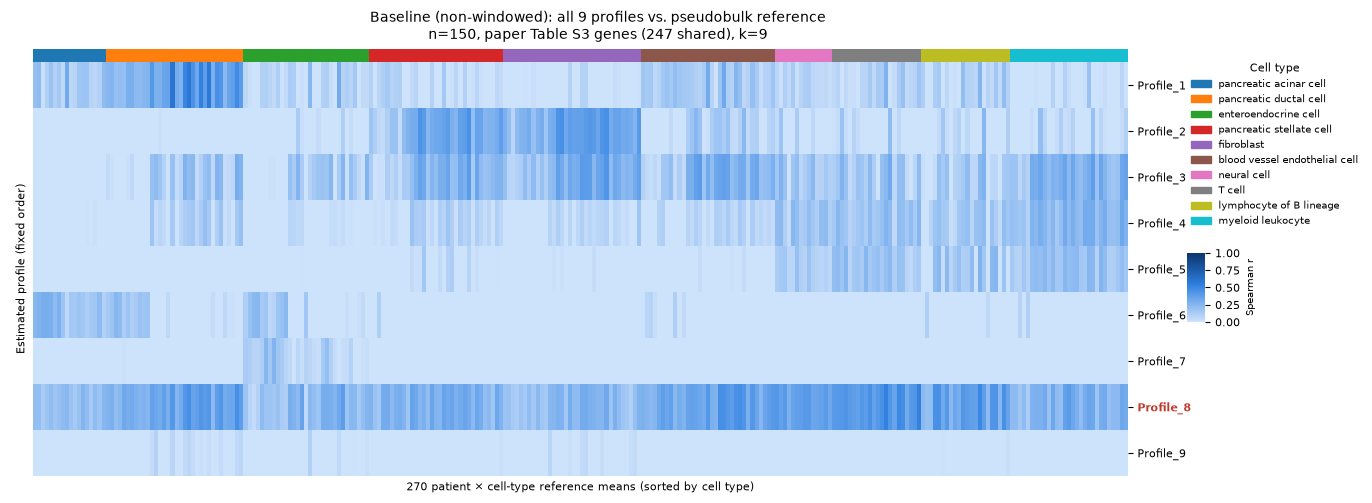

saved paper_duplication/figures/fig_sliding_window_paperGenes_baseline_all_profiles_vs_reference.png


In [3]:
baseline_stage1_dir_paperGenes = os.path.join(XDEC_DIR, "stage1_with_refs_k9_n150_paperGenes")
baseline_profiles = pd.read_csv(os.path.join(baseline_stage1_dir_paperGenes, "cell_type_profiles.tsv"),
                                 sep="\t", index_col=0)
profile_order = [f"Profile_{i}" for i in range(1, 10)]

baseline_genes = [g for g in probe_list if g in refs.index and g in baseline_profiles.index]
if len(baseline_genes) < 3:
    raise ValueError("Insufficient shared genes for the baseline all-profiles heatmap")
combined = pd.concat([reference_means.loc[baseline_genes], baseline_profiles.loc[baseline_genes, profile_order]], axis=1)
baseline_corr_all = combined.corr(method="spearman").loc[profile_order, pb_order]
if not np.isfinite(baseline_corr_all.to_numpy()).all():
    raise ValueError("Undefined correlations in the baseline all-profiles heatmap; check for constant vectors")

grid0 = sns.clustermap(
    baseline_corr_all, row_cluster=False, col_cluster=False,
    col_colors=pb_cell_types.loc[pb_order].map(cell_palette).to_numpy(),
    cmap=seq_blue, vmin=0.0, vmax=1.0,
    xticklabels=False, yticklabels=True, figsize=(12, 4.6),
    cbar_kws={"label": "Spearman r", "ticks": [0, 0.25, 0.5, 0.75, 1]}, dendrogram_ratio=(0.02, 0.02),
)
grid0.ax_heatmap.set_xlabel(f"{len(pb_order)} patient × cell-type reference means (sorted by cell type)")
grid0.ax_heatmap.set_ylabel("Estimated profile (fixed order)")
grid0.ax_heatmap.yaxis.set_label_position("left")
grid0.ax_heatmap.tick_params(axis="y", rotation=0)
for lbl in grid0.ax_heatmap.get_yticklabels():
    if lbl.get_text() == TARGET_PROFILE:
        lbl.set_weight("bold")
        lbl.set_color("#c0392b")

handles0 = [plt.Rectangle((0, 0), 1, 1, color=cell_palette[t]) for t in cell_type_order]
legend0 = grid0.ax_heatmap.legend(
    handles0, cell_type_order, title="Cell type", bbox_to_anchor=(1.05, 1.02),
    loc="upper left", fontsize=7, title_fontsize=8, frameon=False,
)
grid0.fig.suptitle(f"Baseline (non-windowed): all 9 profiles vs. pseudobulk reference\n"
                    f"n=150, paper Table S3 genes ({len(baseline_genes)} shared), k=9", y=1.04, fontsize=10)
grid0.fig.canvas.draw()
bbox0 = legend0.get_window_extent(grid0.fig.canvas.get_renderer()).transformed(grid0.fig.transFigure.inverted())
grid0.cax.set_position([bbox0.x0, bbox0.y0 - 0.20, 0.015, 0.15])
grid0.cax.yaxis.label.set_fontsize(7)

figures_dir = Path("paper_duplication/figures")
figures_dir.mkdir(parents=True, exist_ok=True)
baseline_fig_path = figures_dir / "fig_sliding_window_paperGenes_baseline_all_profiles_vs_reference.png"
grid0.savefig(baseline_fig_path, dpi=200, bbox_inches="tight")
baseline_corr_all.to_csv(baseline_fig_path.with_suffix(".tsv"), sep="\t")
plt.show()
plt.close(grid0.fig)
print("saved", baseline_fig_path)

### Per-window Profile_8 reference correlation

For each of the 111 windows, correlate `Profile_8`'s window-specific Stage 2 mean expression against every patient × cell-type reference column, over the shared paper Table S3 genes. Summary breadth/margin statistics are printed (not plotted separately) to keep this notebook's output to the single heatmap.

In [4]:
window_corr_rows = {}
summary_rows = []

for _, row in manifest.iterrows():
    tag = row["tag"]
    s2_dir = os.path.join(WINDOWS_DIR, f"stage2_{tag}")
    means_path = os.path.join(s2_dir, "stage2_means.tsv")
    if not os.path.exists(means_path):
        raise FileNotFoundError(f"Missing cached Stage 2 output for window {tag}: {means_path}")
    w_means = pd.read_csv(means_path, sep="\t", index_col=0)

    genes = [g for g in probe_list if g in refs.index and g in w_means.index]
    if len(genes) < 10:
        raise ValueError(f"{tag}: insufficient shared genes for correlation")
    combined = pd.concat([reference_means.loc[genes], w_means.loc[genes, [TARGET_PROFILE]]], axis=1)
    correlations = combined.corr(method="spearman")[TARGET_PROFILE].drop(TARGET_PROFILE)
    if not np.isfinite(correlations.to_numpy()).all():
        raise ValueError(f"{tag}: undefined correlations; check for constant expression vectors")
    window_corr_rows[tag] = correlations.loc[pb_order]

    ranked_ref = correlations.sort_values(ascending=False)
    celltype_means = correlations.groupby(pb_cell_types.loc[pb_order]).mean()
    summary_rows.append({
        "window": tag, "start": int(row["start"]), "mean_KRT19_tpm": float(row["mean_KRT19_tpm"]),
        "breadth_celltypes_r_gt_0.3": int((celltype_means > CORR_THRESHOLD).sum()),
        "breadth_columns_r_gt_0.3": int((correlations > CORR_THRESHOLD).sum()),
        "reference_margin": float(ranked_ref.iloc[0] - ranked_ref.iloc[1]),
    })

window_corr_matrix = pd.DataFrame(window_corr_rows).T.loc[manifest["tag"]]
summary_df = pd.DataFrame(summary_rows).sort_values("start").reset_index(drop=True)

print(f"n shared genes: {len(genes)}/{len(probe_list)}")
print(f"breadth (10 cell types, r>0.3): range [{summary_df['breadth_celltypes_r_gt_0.3'].min()}, "
      f"{summary_df['breadth_celltypes_r_gt_0.3'].max()}]")
print(f"breadth (270 columns, r>0.3): range [{summary_df['breadth_columns_r_gt_0.3'].min()}, "
      f"{summary_df['breadth_columns_r_gt_0.3'].max()}]")
print(f"reference margin: range [{summary_df['reference_margin'].min():.4f}, {summary_df['reference_margin'].max():.4f}]")
margin_r = summary_df["reference_margin"].corr(summary_df["mean_KRT19_tpm"], method="spearman")
print(f"Spearman r of margin vs. window mean {RANKING_GENE} TPM: {margin_r:.2f}")

n shared genes: 248/282
breadth (10 cell types, r>0.3): range [6, 10]
breadth (270 columns, r>0.3): range [169, 264]
reference margin: range [0.0003, 0.0328]
Spearman r of margin vs. window mean KRT19 TPM: 0.18


### The visualization: 111 windows × (patient, cell-type) reference

Rows are the 111 overlapping windows, ordered by increasing mean `KRT19` enrichment (bottom = lowest, top = highest); columns are the 270 patient × cell-type reference means, sorted by cell type.

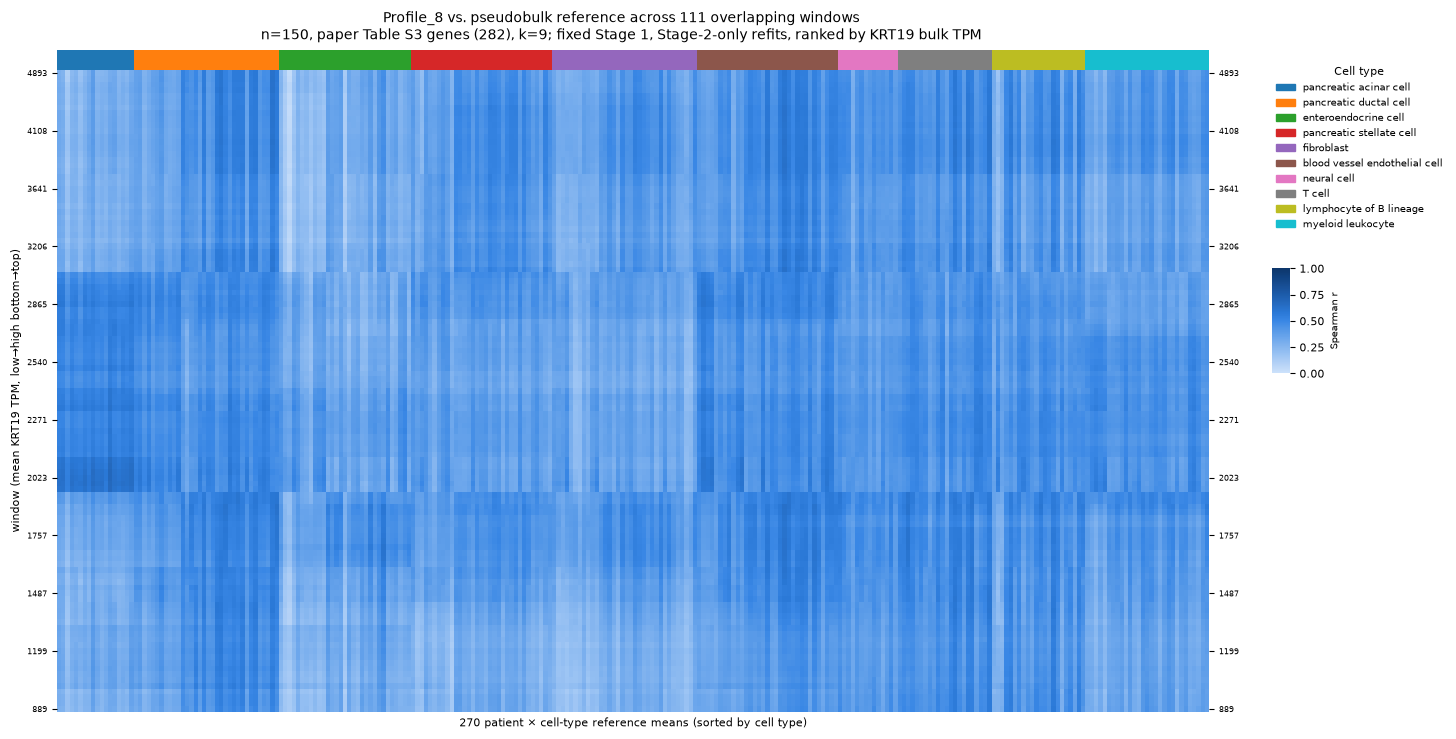

saved paper_duplication/figures/fig_sliding_window_paperGenes_profile_8_vs_reference.png


In [5]:
heatmap_matrix = window_corr_matrix.iloc[::-1]  # lowest enrichment at bottom, highest at top
row_tick_step = 10
row_tick_idx = list(range(0, len(heatmap_matrix), row_tick_step))
row_labels = [f"{manifest.set_index('tag').loc[t, 'mean_KRT19_tpm']:.0f}" for t in heatmap_matrix.index]

grid = sns.clustermap(
    heatmap_matrix, row_cluster=False, col_cluster=False,
    col_colors=pb_cell_types.loc[pb_order].map(cell_palette).to_numpy(),
    cmap=seq_blue, vmin=0.0, vmax=1.0,
    xticklabels=False, yticklabels=False, figsize=(12, 7),
    cbar_kws={"label": "Spearman r", "ticks": [0, 0.25, 0.5, 0.75, 1]}, dendrogram_ratio=(0.02, 0.02),
)
grid.ax_heatmap.set_xlabel(f"{len(pb_order)} patient × cell-type reference means (sorted by cell type)")
grid.ax_heatmap.set_ylabel(f"window (mean {RANKING_GENE} TPM, low→high bottom→top)")
grid.ax_heatmap.set_yticks([i + 0.5 for i in row_tick_idx])
grid.ax_heatmap.set_yticklabels([row_labels[i] for i in row_tick_idx], rotation=0, fontsize=6)
grid.ax_heatmap.yaxis.set_label_position("left")
grid.ax_heatmap.tick_params(axis="y", left=True, labelleft=True)

handles = [plt.Rectangle((0, 0), 1, 1, color=cell_palette[t]) for t in cell_type_order]
legend = grid.ax_heatmap.legend(
    handles, cell_type_order, title="Cell type", bbox_to_anchor=(1.05, 1.02),
    loc="upper left", fontsize=7, title_fontsize=8, frameon=False,
)
grid.fig.suptitle(f"{TARGET_PROFILE} vs. pseudobulk reference across 111 overlapping windows\n"
                   f"n=150, paper Table S3 genes (282), k=9; fixed Stage 1, Stage-2-only refits, ranked by {RANKING_GENE} bulk TPM",
                   y=1.02, fontsize=10)
grid.fig.canvas.draw()
bbox = legend.get_window_extent(grid.fig.canvas.get_renderer()).transformed(grid.fig.transFigure.inverted())
grid.cax.set_position([bbox.x0, bbox.y0 - 0.20, 0.015, 0.15])
grid.cax.yaxis.label.set_fontsize(7)

figures_dir = Path("paper_duplication/figures")
figures_dir.mkdir(parents=True, exist_ok=True)
heatmap_path = figures_dir / f"fig_sliding_window_paperGenes_{TARGET_PROFILE.lower()}_vs_reference.png"
grid.savefig(heatmap_path, dpi=200, bbox_inches="tight")
window_corr_matrix.to_csv(heatmap_path.with_suffix(".tsv"), sep="\t")
plt.show()
plt.close(grid.fig)
print("saved", heatmap_path)